# 📊**Trabajo Práctico – Redes Neuronales**

##  **Aplicación de redes neuronales a la predicción del tipo de baja en accidentes laborales de la construcción en Argentina**
Integrantes: Grupo 10

* Hernán Fahoto
* Julieta Cortinez
* Fernanda Roman
* Elian Lewicki
* Janneth Chura

**Materia:** Desarrollo de Sistemas de IA

**Docente:** Elisabeth Pose

**Año:** 2026


## 🏗️ **Redes neuronales aplicadas a la predicción del tipo de baja en accidentes laborales de la construcción en Argentina**

En este trabajo buscamos aplicar técnicas de Inteligencia Artificial para abordar una problemática importante en el sector de la construcción: los accidentes laborales y sus consecuencias, tomando como tema de análisis los tipos de baja.

Este proyecto continúa el trabajo que realizamos anteriormente con **Machine Learning**, donde utilizamos el algoritmo **Random Forest** para predecir el tipo de baja y obtuvimos una exactitud ( `accuracy` ) del **36,67%**.

A partir del mismo conjunto de datos y de las distintas etapas de análisis que fuimos desarrollando, en esta nueva etapa vamos a trabajar con redes neuronales para analizar los datos, identificar patrones y realizar predicciones. Nuestro objetivo es evaluar si este modelo nos permite mejorar la exactitud obtenida anteriormente y lograr mejores resultados en la predicción del tipo de baja en los accidentes laborales de la construcción en Argentina.

## 1️⃣. **Definición del problema**

El problema que buscamos resolver es la predicción del tipo de baja en accidentes laborales de la construcción en Argentina, utilizando las características registradas en nuestra base de datos.

Para ello, vamos a entrenar una red neuronal que aprenda a reconocer patrones entre los datos de cada registro y el tipo de baja correspondiente.

## 2️⃣. **Elección y justificación de la arquitectura de la red neuronal**


Para este trabajo elegimos una **red neuronal de tipo Feedforward (FNN)** o **Perceptrón Multicapa (MLP)**. Esta arquitectura permite procesar las variables de nuestra base de datos y aprender relaciones entre ellas para realizar la clasificación.

La elegimos porque nuestro conjunto de datos es tabular (datos estructurados en filas y columnas), por lo que arquitecturas como las redes convolucionales (CNN, pensadas para imágenes) o recurrentes (RNN, pensadas para texto o secuencias) no aplican a nuestro caso. Además, es una opción clara de implementar en Colab y nos permite evaluar si una red neuronal logra mejorar la exactitud que obtuvimos previamente con Random Forest.

## 3️⃣. **Preparación de los datos**

Para entrenar nuestra red neuronal, vamos a utilizar el conjunto de datos de siniestralidad en la construcción que trabajamos en las etapas anteriores.

En esta etapa, seleccionaremos las variables explicativas de entrada (**X**) y mantendremos como variable objetivo a  `gravedad_baja`  (**y**). Para que la red neuronal pueda procesar la información correctamente, convertiremos las variables categóricas a formato numérico, escalaremos las variables para que estén todas en la misma escala y dividiremos el conjunto de datos en grupos de entrenamiento y prueba.

In [ ]:
# Importamos las librerías necesarias para procesamiento de datos
import pandas as pd
import numpy as np

# Importamos las librerías para visualización gráfica
import matplotlib.pyplot as plt
import seaborn as sns

# Importamos las herramientas de Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Importamos TensorFlow y Keras para la red neuronal
import tensorflow as tf
from tensorflow import keras
from keras import layers

# Importamos Random para la aleatoriedad y reproducibilidad
import random

# Confirmamos la carga exitosa de librerías
print("Librerías cargadas exitosamente.")

# Carga del dataset desde Google Drive
url = "https://drive.google.com/uc?export=download&id=1QTX0TqCM07Lgb5EertT8CwITVplR2K_I" # URL Dataset Limpio
df = pd.read_csv(url)

# Comprobamos las primeras 5 filas
df.head()

Librerías cargadas exitosamente.


,id_caso,ano_notificacion,provincia,rama_actividad,tipo_siniestro,edad_trabajador,tipo_lesion,dias_baja,tamano_empresa,gravedad_baja
0,SRT-2024-100000,2024,Buenos Aires,Construcción De Edificios,Accidente De Trabajo,45,Cortes Y Escoriaciones,16.0,Pequeña (1-10),Baja Mediana
1,SRT-2024-100001,2024,Entre Ríos,Construcción De Edificios,Accidente De Trabajo,44,Quemaduras,17.0,Mediana (11-50),Baja Mediana
2,SRT-2024-100002,2024,Córdoba,Terminación De Edificios Y Pintura,Accidente De Trabajo,46,Esguinces Y Torceduras,67.0,Corporación (+200),Baja Prolongada
3,SRT-2024-100003,2024,Santa Fe,Obras Hidráulicas Y Viales,Accidente De Trabajo,49,Esguinces Y Torceduras,68.0,Corporación (+200),Baja Prolongada
4,SRT-2024-100004,2024,Buenos Aires,Construcción De Edificios,Accidente De Trabajo,60,Contusiones,28.0,Pequeña (1-10),Baja Mediana


In [ ]:
# Separamos las variables de entrada (X) descartando identificadores y columnas derivadas, y la variable objetivo (y)
X = df.drop(columns=["gravedad_baja", "id_caso", "dias_baja"])
y = df["gravedad_baja"]

# Identificamos columnas categóricas y numéricas
categoricas = X.select_dtypes(include=["object"]).columns.tolist()
numericas = X.select_dtypes(include=["number"]).columns.tolist()

# Dividimos los datos en entrenamiento (80%) y prueba (20%) de forma estratificada
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Registros para entrenamiento: {X_train_raw.shape[0]}")
print(f"Registros para prueba: {X_test_raw.shape[0]}")

Registros para entrenamiento: 2040
Registros para prueba: 510


In [ ]:
# Aplicamos codificación One-Hot a las variables categóricas (manteniendo todas las columnas para la red neuronal)
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X_train_cat = encoder.fit_transform(X_train_raw[categoricas])
X_test_cat = encoder.transform(X_test_raw[categoricas])
print("Codificación de variables categóricas completada.")

# Normalizamos y escalamos las variables numéricas
scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train_raw[numericas])
X_test_num_scaled = scaler.transform(X_test_raw[numericas])
print("Preparación y normalización de variables numéricas completada.")

# Combinamos las características procesadas (numéricas escaladas + categóricas codificadas)
X_train = pd.concat([
    pd.DataFrame(X_train_num_scaled, columns=numericas, index=X_train_raw.index),
    pd.DataFrame(X_train_cat, columns=encoder.get_feature_names_out(categoricas), index=X_train_raw.index)
], axis=1)

X_test = pd.concat([
    pd.DataFrame(X_test_num_scaled, columns=numericas, index=X_test_raw.index),
    pd.DataFrame(X_test_cat, columns=encoder.get_feature_names_out(categoricas), index=X_test_raw.index)
], axis=1)

# Codificamos las 4 categorías de la variable objetivo a números (0, 1, 2, 3)
le = LabelEncoder()
y_train = le.fit_transform(y_train_raw)
y_test = le.transform(y_test_raw)
print("Codificación de la variable objetivo completada.")

# Confirmamos la finalización del preprocesamiento y mostramos las dimensiones finales
print("\nPreprocesamiento completado exitosamente.")
print(f"Dimensiones finales de X_train (capa de entrada): {X_train.shape}")
print(f"Dimensiones finales de X_test: {X_test.shape}")
print(f"Categorías objetivo codificadas: {le.classes_}")

Codificación de variables categóricas completada.
Preparación y normalización de variables numéricas completada.
Codificación de la variable objetivo completada.

Preprocesamiento completado exitosamente.
Dimensiones finales de X_train (capa de entrada): (2040, 37)
Dimensiones finales de X_test: (510, 37)
Categorías objetivo codificadas: ['Baja Corta' 'Baja Mediana' 'Baja Prolongada' 'Sin Baja']


## 4️⃣. **Implementación y entrenamiento del modelo en Keras**

Diseñamos una arquitectura de Red Neuronal directa (Perceptrón Multicapa) orientada a clasificar la categoría de baja laboral de los trabajadores según la variable objetivo (sin baja, baja corta, baja mediana y baja prolongada).

Para definir la estructura de la red, consideramos los siguientes aspectos clave:

**Capa de Entrada:** Recibe las 37 características que preprocesamos en el paso anterior.

**Capa Oculta:** Definimos una capa densa con función de activación **ReLU** para permitir que la red capture relaciones no lineales complejas entre las variables de entrada.

**Capa de Salida:** Incorporamos una capa densa con 4 neuronas y función de activación **Softmax**, la cual transforma las salidas en una distribución de probabilidades para cada una de las 4 categorías de baja.

**Compilación del Modelo:** Configuramos el optimizador **Adam** para ajustar los pesos de forma eficiente, la función de pérdida Entropía Cruzada Categórica Esparsa **(Sparse Categorical Crossentropy)** acorde a nuestras etiquetas codificadas, y la métrica de Precisión (Accuracy) para monitorear el rendimiento.

A continuación, construimos la red neuronal, mostramos su resumen estructural y procedemos al entrenamiento con los datos preparados.

In [ ]:
# Fijamos las semillas aleatorias para reproducir los resultados
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# Construimos nuestra red neuronal (Perceptrón Multicapa)
modelo = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(4, activation="softmax")])

# Configuramos la red neuronal para el entrenamiento
modelo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

# Confirmamos la compilación y mostramos el resumen del modelo
print("Modelo definido y compilado correctamente.")
modelo.summary()

Modelo definido y compilado correctamente.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,692 (10.52 KB)

 Trainable params: 2,692 (10.52 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4301 - loss: 1.1912 - val_accuracy: 0.4559 - val_loss: 1.1744
Epoch 2/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4602 - loss: 1.1458 - val_accuracy: 0.4314 - val_loss: 1.1655
Epoch 3/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4749 - loss: 1.1310 - val_accuracy: 0.4485 - val_loss: 1.1619
Epoch 4/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4798 - loss: 1.1197 - val_accuracy: 0.4510 - val_loss: 1.1600
Epoch 5/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4902 - loss: 1.1098 - val_accuracy: 0.4510 - val_loss: 1.1585
Epoch 6/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4963 - loss: 1.1007 - val_accuracy: 0.4485 - val_loss: 1.1576
Epoch 7/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5000 - loss: 1.0925 - val_accuracy: 0.4485 - val_loss: 1.1571
Epoch 8/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5006 - loss: 1.0847 - val_accuracy: 0.4510 - val_loss

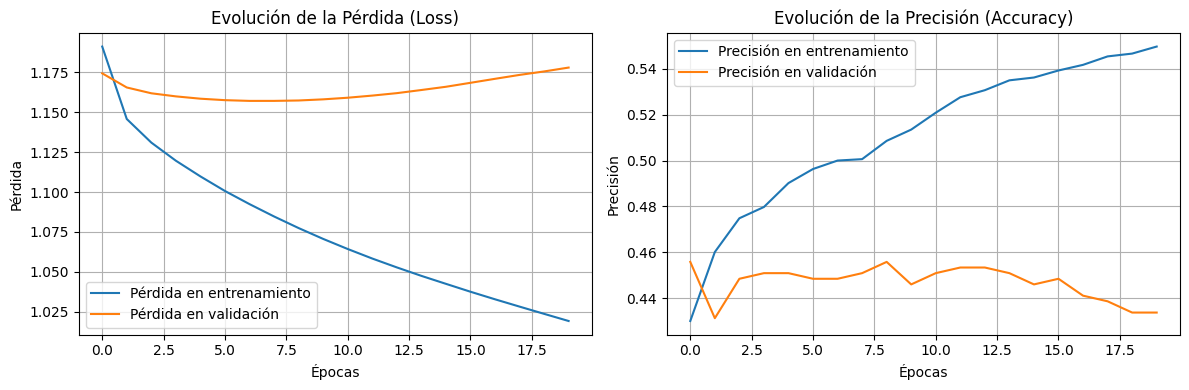

Entrenamiento completado y gráficos de evolución generados.


In [ ]:
# Entrenamos la red neuronal con los datos preparados
historial = modelo.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2, verbose=1)

# Graficamos la evolución de la pérdida y la precisión durante el entrenamiento
plt.figure(figsize=(12, 4))

# Gráfico de Pérdida (Loss)
plt.subplot(1, 2, 1)
plt.plot(historial.history["loss"], label="Pérdida en entrenamiento")
plt.plot(historial.history["val_loss"], label="Pérdida en validación")
plt.title("Evolución de la Pérdida (Loss)")
plt.xlabel("Épocas")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)

# Gráfico de Precisión (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(historial.history["accuracy"], label="Precisión en entrenamiento")
plt.plot(historial.history["val_accuracy"], label="Precisión en validación")
plt.title("Evolución de la Precisión (Accuracy)")
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.legend()
plt.grid(True)


print()
plt.tight_layout()
print()
plt.show()

print("Entrenamiento completado y gráficos de evolución generados.")

### **Análisis de la evolución del entrenamiento**
Al observar los gráficos de la pérdida y la precisión a lo largo de las 20 épocas, podemos destacar los siguientes puntos:

**Evolución en entrenamiento:** La pérdida en el conjunto de entrenamiento disminuye de manera constante y sostenida hasta alcanzar un valor cercano a 1.02, mientras que la precisión aumenta progresivamente hasta superar el **54.5%**. Esto indica que la red aprende de forma continua sobre los datos de entrenamiento.

**Evolución en validación:** La precisión en el conjunto de validación se estabiliza en un rango aproximado del **44% al 45%**. Observamos claramente que a partir de la **época 5 o 6**, la pérdida de validación deja de decrecer y comienza una tendencia al alza, separándose de la curva de entrenamiento.

**Diagnóstico:** Este comportamiento evidencia un claro **sobreajuste (overfitting)**, donde el modelo comienza a memorizar los patrones específicos de los datos de entrenamiento en lugar de generalizar para nuevos datos.

Este análisis nos confirma que extender el entrenamiento a más épocas no aportaría mejoras significativas (e incluso empeoraría la generalización), por lo que procedemos a utilizar el modelo en este punto para evaluar su rendimiento real sobre el conjunto de datos de prueba (*test*).

## 5️⃣. **Mostrar y analizar los resultados obtenidos**

Una vez completado el entrenamiento de la red neuronal, evaluamos su rendimiento real sobre el conjunto de datos de prueba (`X_test` y `y_test`), el cual se mantuvo completamente aislado durante todo el proceso.

Para analizar los resultados de manera integral, realizamos los siguientes pasos:

 **Evaluación del modelo:** Calculamos la pérdida y la precisión general en el conjunto de prueba.

 **Reporte de clasificación:** Examinamos las métricas detalladas (precisión, sensibilidad y puntuación F1) para cada una de las 4 categorías de baja laboral.

 **Matriz de confusión:** Graficamos la matriz para observar visualmente los aciertos y los errores de predicción entre las distintas clases.

In [ ]:
# Evaluamos la red neuronal con el conjunto de datos de prueba
loss_test, accuracy_test = modelo.evaluate(X_test, y_test, verbose=0)

print(f"Pérdida en prueba (Loss): {loss_test:.4f}")
print(f"Precisión en prueba (Accuracy): {accuracy_test:.4f}")
print(f"Precisión porcentual: {accuracy_test * 100:.2f}%\n")

# Generamos las predicciones sobre el conjunto de prueba
y_pred_prob = modelo.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

# Imprimimos el reporte detallado por categoría de baja
print("Reporte de clasificación por categoría:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

Pérdida en prueba (Loss): 1.1924
Precisión en prueba (Accuracy): 0.4373
Precisión porcentual: 43.73%

Reporte de clasificación por categoría:
                 precision    recall  f1-score   support

     Baja Corta       0.39      0.27      0.32       186
   Baja Mediana       0.46      0.69      0.56       232
Baja Prolongada       0.35      0.18      0.24        60
       Sin Baja       0.00      0.00      0.00        32

       accuracy                           0.44       510
      macro avg       0.30      0.29      0.28       510
   weighted avg       0.39      0.44      0.40       510



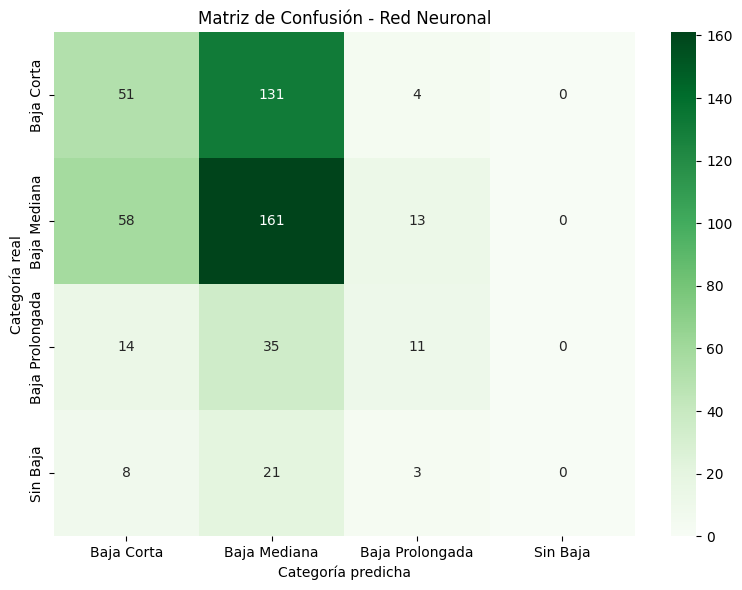

In [ ]:
# Obtenemos la matriz de confusión
matriz = confusion_matrix(y_test, y_pred)

# Graficamos la matriz de confusión de la red neuronal
plt.figure(figsize=(8, 6))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.title("Matriz de Confusión - Red Neuronal")
plt.tight_layout()
plt.show()

### **Análisis de los resultados de prueba**

Al evaluar nuestra red neuronal sobre los 510 registros del conjunto de prueba, obtuvimos una precisión (accuracy) general del **43.73%** y una pérdida (loss) de **1.1924**. Este resultado indica que el modelo logra clasificar correctamente una parte de los casos, aunque aún presenta dificultades para predecir con exactitud el tipo de baja laboral.
Al analizar en detalle la Matriz de Confusión, observamos un desempeño desigual entre las categorías:
* **Baja Mediana**: Es la categoría con mejor rendimiento, alcanzando una sensibilidad (recall) del **69%** (**161 aciertos** sobre un total de **232** casos reales). La red identifica correctamente a la mayoría de las personas en este grupo.
* **Baja Corta**: Obtiene un desempeño intermedio, registrando **51 aciertos** sobre un total de **186** casos reales (un recall del **27%**).
* **Baja Prolongada**: Presenta un rendimiento bajo, con una sensibilidad de solo el **18%** (**11 aciertos** sobre **60** casos), lo que significa que la red suele confundirla frecuentemente con otras categorías.
* **Sin Baja**: El modelo no logró clasificar correctamente ningún registro de esta categoría (**0 aciertos** sobre **32** casos), debido a que es la clase con menor cantidad de ejemplos en el conjunto de datos (**desbalance de clases**).

En conclusión, la matriz de confusión y el reporte nos confirman que el modelo concentró sus predicciones en las clases mayoritarias (**Baja Mediana** y **Baja Corta**), teniendo mayores dificultades con las clases de menor frecuencia.

## **Interfaz de usuario: demostración de la red neuronal**

Para facilitar la utilización de nuestro modelo, desarrollamos una interfaz de usuario externa que permite seleccionar las características de un accidente laboral y obtener una predicción de la categoría de `(gravedad_baja`), definida según la cantidad de días de baja.

La interfaz utiliza la red neuronal entrenada y muestra la categoría predicha junto con las probabilidades estimadas. De esta manera, podemos probar distintas combinaciones de datos y observar cómo responde el modelo sin necesidad de ejecutar manualmente el código de Google Colab.

**Enlace a la interfaz:** https://redesneuronalesten.vercel.app/


## 6️⃣ . **Conclusiones y posibles mejoras**

En este trabajo implementamos y evaluamos una red neuronal (**Perceptrón Multicapa**) para clasificar la categoría de baja laboral a partir de datos de accidentes en el sector de la construcción en Argentina.

Al evaluar la red sobre el conjunto de prueba, obtuvimos una precisión del **43.73%**. Al compararlo con el resultado obtenido en el trabajo práctico anterior con Random Forest (**36.67%**), observamos una mejora en la capacidad predictiva general del modelo.

Sin embargo, los resultados muestran que la red aún presenta dificultades para clasificar correctamente todas las categorías. Al analizar la matriz de confusión y el reporte, notamos que el modelo aprendió bien las clases con más datos (**Baja Mediana** y **Baja Corta**), pero le costó predecir las clases con pocos ejemplos (**Baja Prolongada** y **Sin Baja**).

Como **posibles mejoras** para futuros trabajos, planteamos:

**Balanceo de datos:** Aplicar técnicas para equilibrar la cantidad de registros por categoría, de modo que la red tenga más ejemplos para aprender sobre las clases minoritarias (**Sin Baja** y **Baja Prolongada**).

**Selección de variables:** Analizar en detalle qué columnas o características aportan más información útil para la predicción y descartar las que generen ruido.

**Ajuste de la red:** Probar variando la cantidad de neuronas, la cantidad de épocas o la estructura de la red para encontrar una configuración que generalice mejor los datos.

Este trabajo nos permitió aplicar redes neuronales a un caso real de seguridad laboral y comprender la importancia de analizar detalladamente las métricas antes de utilizar un modelo en la toma de decisiones.